### Variables calculées pour une échelle donnée (94 variables)

| Bloc | Calcul | Nombre |
|---|---|:---:|
| Statistiques | moyenne, écart-type, min, max des 20 signaux | 80 |
| Fréquentiel (sur les 4 normes) | fréquence dominante, énergie, entropie spectrale | 12 |
| Ratios | norme moyenne cou / dos, pour l'accéléromètre et le gyroscope | 2 |

Le nom d'une variable suit le schéma `signal_statistique_échelle`, par exemple `ANeck_norm_std_w2s`.

### Les quatre expériences

| Expérience | Contenu | Nb de variables | Question posée |
|---|---|:---:|---|
| `ancienne_baseline_1s` | moyenne + écart-type des 20 signaux sur 1 s, + 2 ratios | 42 | Point de départ |
| `complet_1s` | les 94 variables, sur 1 s | 94 | Min, max et fréquentiel aident-ils ? |
| `multi_echelle` | les 94 variables sur 1 s, 2 s et 4 s | 282 | Le contexte temporel aide-t-il ? |
| `multi_echelle+profil` | + `Weight`, `Age months`, `Gender`, `NeuteringStatus` | 286 | Le profil du chien aide-t-il ? |

In [1]:
import sys
from pathlib import Path

# Racine du projet ajoutée au chemin d'import (le notebook est dans notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import json
from src import data, features, labels, modeling, evaluation, viz

In [2]:
windows = data.load_table(cfg.WINDOWS_FILE)
dogs = data.load_dogs()
train_ids, test_ids = data.load_split()

## 1. Définition de la tâche et classes rares

Le seuil de 500 fenêtres est décidé sur le train et appliqué au train et au test. Conséquence: les scores ne portent que sur les classes conservées ; les fenêtres de test des classes exclues
ne sont pas évaluées (leur part est affichée ci-dessous).

In [3]:
task = labels.select_task_windows(windows, "general", min_purity=cfg.MIN_PURITY)
task = task.merge(dogs[["DogID"] + cfg.STATIC_FEATURES], on="DogID", how="left")
train_all, test_all = task[task["DogID"].isin(train_ids)], task[task["DogID"].isin(test_ids)]
train, test, classes, table_classes = labels.filter_rare_classes(train_all, test_all,
                                                                 min_count=cfg.MIN_WINDOWS_PER_CLASS)
display(table_classes)
table_classes.to_csv(cfg.TABLES_DIR / "04_classes_general.csv")
print(f"{len(classes)} classes conservées sur {len(table_classes)}")
print(f"Part des fenêtres de test exclues (classes rares) : {table_classes.attrs['part_test_exclue']:.1%}")
absentes = table_classes.index[table_classes["conservee"] & (table_classes["n_fenetres_test"] == 0)].tolist()
print("Classes conservées mais absentes du test (non évaluables) :", absentes or "aucune")
print(f"Train : {len(train):,} fenêtres ({train['DogID'].nunique()} chiens) | "
      f"Test : {len(test):,} fenêtres ({test['DogID'].nunique()} chiens)")

,n_fenetres_train,n_fenetres_test,conservee
target,,,
Lying chest,15722,4607,True
Sniffing,15065,4165,True
Panting,12562,2632,True
Playing,12545,3945,True
Trotting,10553,2746,True
Walking,9864,3099,True
Sitting,6723,3210,True
Standing,6319,2234,True
Eating,2176,195,True


11 classes conservées sur 17
Part des fenêtres de test exclues (classes rares) : 0.7%
Classes conservées mais absentes du test (non évaluables) : aucune
Train : 93,124 fenêtres (36 chiens) | Test : 27,654 fenêtres (9 chiens)


## 2. Recherche d'hyperparamètres et comparaison par validation croisée

In [4]:
MODELES = None   # None = tous ; ex. ["Dummy_majoritaire", "Dummy_stratifie", "RandomForest", "XGBoost"]

experiences = {name: features.feature_set(windows, name) for name in features.FEATURE_SET_NAMES}
experiences["multi_echelle+profil"] = experiences["multi_echelle"] + cfg.STATIC_FEATURES

resumes, bundles = [], {}
for exp, cols in experiences.items():
    resume, b = modeling.run_experiment(train, cols, experiment=exp, task="general", models=MODELES)
    resumes.append(resume)
    bundles[exp] = b
resultats_cv = pd.concat(resumes, ignore_index=True)
resultats_cv.to_csv(cfg.TABLES_DIR / "04_resultats_cv_general.csv", index=False)
display(resultats_cv.drop(columns=["meilleurs_params"]).round(3))

[ancienne_baseline_1s] Dummy_majoritaire ... F1 macro CV = 0.025 ± 0.002 (3.6 s)
[ancienne_baseline_1s] Dummy_stratifie ... F1 macro CV = 0.090 ± 0.004 (2.9 s)
[ancienne_baseline_1s] LogisticRegression ... F1 macro CV = 0.618 ± 0.026 (77.6 s)
[ancienne_baseline_1s] RandomForest ... F1 macro CV = 0.668 ± 0.020 (409.2 s)
[ancienne_baseline_1s] XGBoost ... F1 macro CV = 0.690 ± 0.017 (300.3 s)
[complet_1s] Dummy_majoritaire ... F1 macro CV = 0.025 ± 0.002 (0.3 s)
[complet_1s] Dummy_stratifie ... F1 macro CV = 0.090 ± 0.004 (0.3 s)
[complet_1s] LogisticRegression ... F1 macro CV = 0.642 ± 0.025 (116.3 s)
[complet_1s] RandomForest ... F1 macro CV = 0.668 ± 0.011 (504.2 s)
[complet_1s] XGBoost ... F1 macro CV = 0.688 ± 0.024 (375.0 s)
[multi_echelle] Dummy_majoritaire ... F1 macro CV = 0.025 ± 0.002 (0.7 s)
[multi_echelle] Dummy_stratifie ... F1 macro CV = 0.090 ± 0.004 (1.0 s)
[multi_echelle] LogisticRegression ... F1 macro CV = 0.678 ± 0.022 (236.2 s)
[multi_echelle] RandomForest ... F1 ma

,experience,tache,modele,f1_macro_cv_moy,f1_macro_cv_std,f1_macro_train_moy,n_variables,n_variables_retenues,duree_s
0,ancienne_baseline_1s,general,XGBoost,0.690,0.017,0.945,42,17,300.3
1,ancienne_baseline_1s,general,RandomForest,0.668,0.020,0.957,42,17,409.2
2,ancienne_baseline_1s,general,LogisticRegression,0.618,0.026,0.673,42,17,77.6
3,ancienne_baseline_1s,general,Dummy_stratifie,0.090,0.004,0.091,42,42,2.9
4,ancienne_baseline_1s,general,Dummy_majoritaire,0.025,0.002,0.026,42,42,3.6
5,complet_1s,general,XGBoost,0.688,0.024,0.962,94,29,375.0
6,complet_1s,general,RandomForest,0.668,0.011,0.934,94,29,504.2
7,complet_1s,general,LogisticRegression,0.642,0.025,0.705,94,32,116.3
8,complet_1s,general,Dummy_stratifie,0.090,0.004,0.091,94,94,0.3
9,complet_1s,general,Dummy_majoritaire,0.025,0.002,0.026,94,94,0.3


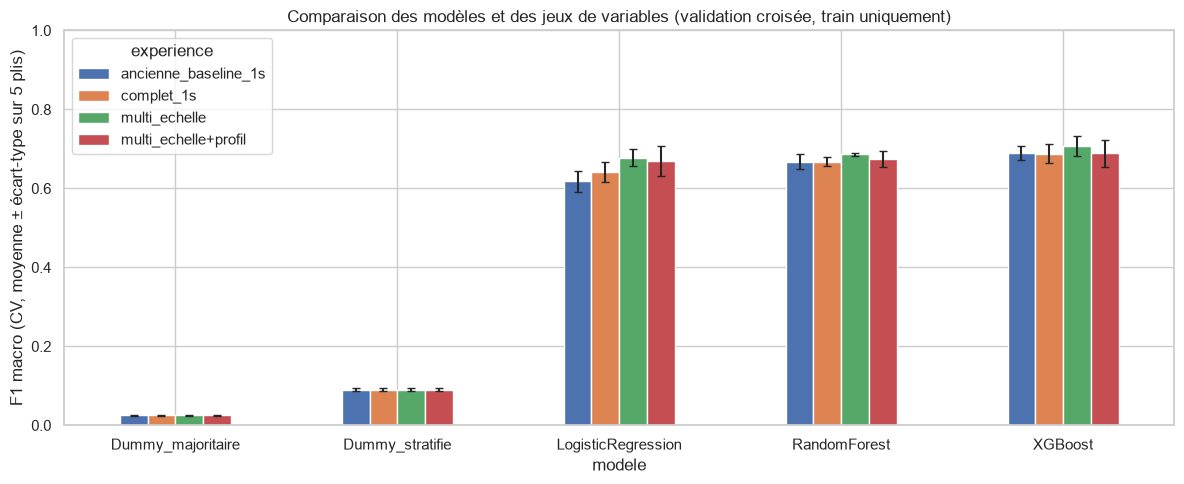

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
pivot_m = resultats_cv.pivot(index="modele", columns="experience", values="f1_macro_cv_moy")
pivot_s = resultats_cv.pivot(index="modele", columns="experience", values="f1_macro_cv_std")
pivot_m[list(experiences)].plot.bar(yerr=pivot_s[list(experiences)], ax=ax, capsize=3)
ax.set_ylabel("F1 macro (CV, moyenne ± écart-type sur 5 plis)")
ax.set_title("Comparaison des modèles et des jeux de variables (validation croisée, train uniquement)")
ax.set_ylim(0, 1); plt.xticks(rotation=0); plt.tight_layout(); viz.savefig(fig, "04_comparaison_cv"); plt.show()

**Important pour la lecture** :
- les `Dummy` donnent le plancher : tout modèle utile doit les dépasser nettement ; --> largement OK
- l'écart entre F1 train et F1 CV (tableau ci-dessus) mesure le surapprentissage ; --> beaucoup plus haut sur le train mais à prévoir au vu des modèles entraînés, ne veux pas forcément dire que c'est du surapprentissage.
- deux expériences dont les barres d'erreur se chevauchent largement ne sont pas réellement départagées. --> pour le modèle retenu (XGBoost multi_echelle), le chevauchement est très léger.

## 3. Choix du modèle final (sur la CV uniquement)

In [6]:
meilleurs = {exp: modeling.best_bundle(b) for exp, b in bundles.items()}
final = max(meilleurs.values(), key=lambda b: b["cv_mean"])
print(f"Modèle retenu : {final['model_name']} / {final['experiment']} "
      f"(F1 macro CV = {final['cv_mean']:.3f} ± {final['cv_std']:.3f})")
print("Hyperparamètres :", final["best_params"])

pointeur = {"task": "general", "experiment": final["experiment"], "model_name": final["model_name"]}
(cfg.TABLES_DIR / "meilleur_modele_general.json").write_text(json.dumps(pointeur, indent=2))

Modèle retenu : XGBoost / multi_echelle (F1 macro CV = 0.707 ± 0.026)
Hyperparamètres : {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 400}


83

## 4. Évaluation sur le test

Le tableau évalue le meilleur modèle (choisi par CV) **de chaque expérience**. Il est informatif : aucune
décision n'est prise à partir de lui. Le modèle final reste celui choisi par CV ci-dessus.

In [7]:
lignes = []
for exp, b in meilleurs.items():
    pred, _ = modeling.predict(b, test)
    m = evaluation.compute_metrics(test["target"], pred, labels=classes)
    lignes.append({"experience": exp, "modele": b["model_name"], "f1_macro_cv": b["cv_mean"], **m})
for dummy in modeling.DUMMY_MODELS:
    b = bundles["multi_echelle"][dummy]
    pred, _ = modeling.predict(b, test)
    lignes.append({"experience": "-", "modele": dummy, "f1_macro_cv": b["cv_mean"],
                   **evaluation.compute_metrics(test["target"], pred, labels=classes)})
resultats_test = pd.DataFrame(lignes)
resultats_test.to_csv(cfg.TABLES_DIR / "04_resultats_test_general.csv", index=False)
display(resultats_test.round(3))

,experience,modele,f1_macro_cv,exactitude,exactitude_equilibree,f1_macro,f1_ponderee,precision_macro,rappel_macro,n_fenetres
0,ancienne_baseline_1s,XGBoost,0.690,0.765,0.715,0.690,0.772,0.695,0.715,27654
1,complet_1s,XGBoost,0.688,0.773,0.721,0.701,0.779,0.708,0.721,27654
2,multi_echelle,XGBoost,0.707,0.792,0.723,0.720,0.795,0.734,0.723,27654
3,multi_echelle+profil,XGBoost,0.688,0.791,0.734,0.721,0.795,0.731,0.734,27654
4,-,Dummy_majoritaire,0.025,0.167,0.091,0.026,0.048,0.015,0.091,27654
5,-,Dummy_stratifie,0.090,0.121,0.089,0.088,0.120,0.090,0.089,27654


## 5. Analyse détaillée du modèle final

,precision,recall,f1-score,support
Lying chest,0.767,0.746,0.756,4607
Sniffing,0.962,0.995,0.978,4165
Panting,0.418,0.459,0.438,2632
Playing,0.949,0.878,0.912,3945
Trotting,0.902,0.962,0.931,2746
Walking,0.938,0.956,0.947,3099
Sitting,0.739,0.635,0.683,3210
Standing,0.596,0.632,0.614,2234
Eating,0.180,0.441,0.255,195
Pacing,0.657,0.526,0.584,390


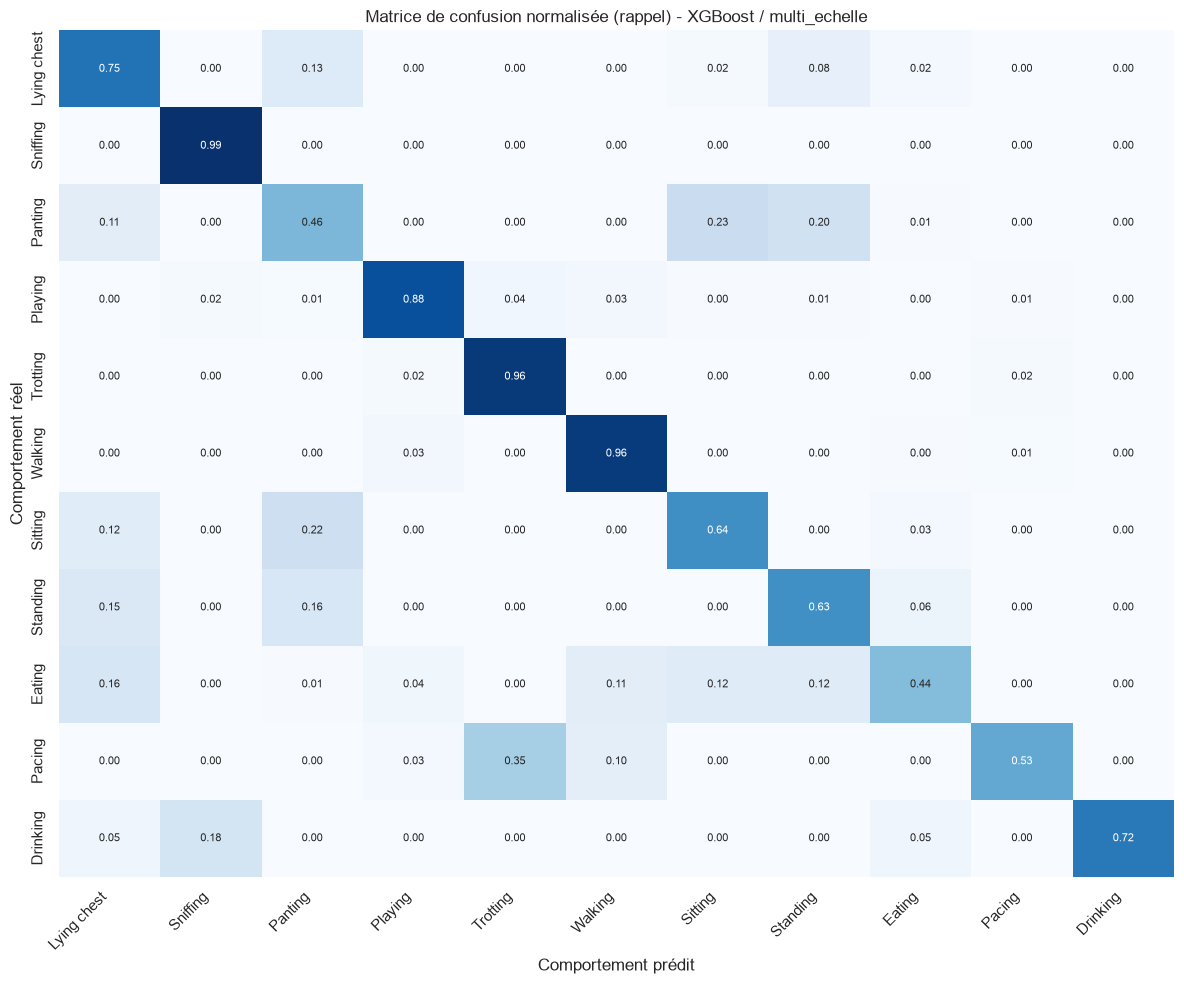

In [8]:
pred, proba = modeling.predict(final, test)
res = test[["window_id", "DogID", "TestNum", "segment", "t_center", "target",
            "behavior_1", "behavior_2", "behavior_3"]].copy()
res["pred"] = pred
proba_cols = [f"proba_{c}" for c in final["label_encoder"].classes_]
res = pd.concat([res.reset_index(drop=True), pd.DataFrame(proba, columns=proba_cols)], axis=1)
data.save_table(res, cfg.PROCESSED_DIR / "predictions_test_general.parquet")

display(evaluation.named_report(res["target"], res["pred"], labels=classes))
fig, ax = plt.subplots(figsize=(12, 10))
evaluation.plot_confusion(res["target"], res["pred"], classes, ax=ax,
                          title=f"Matrice de confusion normalisée (rappel) - {final['model_name']} / {final['experiment']}")
plt.tight_layout(); viz.savefig(fig, "04_confusion_general"); plt.show()

**Lecture de la matrice** : la diagonale est le rappel par classe. Aucune grosse confusion entre la marche et le trot, une certaine confusion entre le trot et la course (Trotting et Pacing). D'autres confusions liées à le présence de labels de différentes familles dans Behavior_1/2/3 : entre Panting et Sitting / Standing : on peut supposer que le chien était à la fois en train d'halèter et assis / debout.

### Score par chien de test

Le chien est l'unité statistique pertinente : un score global agrège des fenêtres très corrélées. La
dispersion entre chiens donne une idée honnête de la fiabilité du score.

,DogID,n_fenetres,exactitude,f1_macro
0,16,4103,0.756,0.686
1,30,3473,0.812,0.602
2,33,1969,0.808,0.520
3,34,4296,0.899,0.604
4,41,3196,0.753,0.656
5,55,1749,0.838,0.760
6,70,2489,0.619,0.543
7,73,2657,0.911,0.676
8,74,3722,0.725,0.638


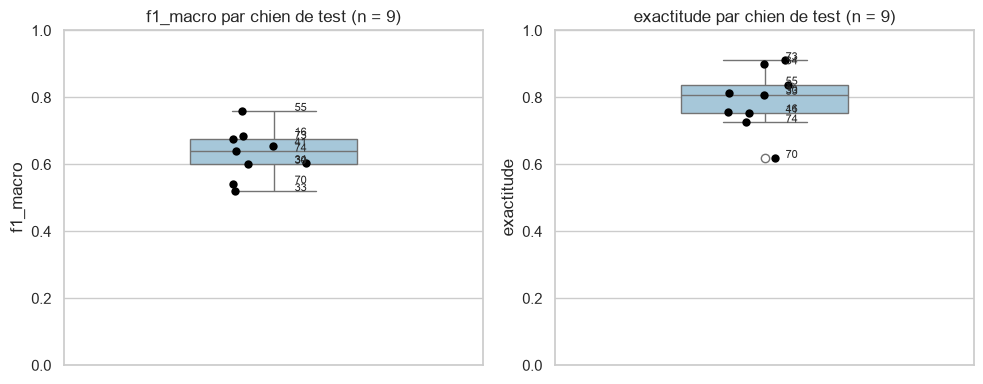

F1 macro par chien : 0.632 ± 0.074


In [9]:
par_chien = evaluation.per_dog_scores(res)
display(par_chien.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
evaluation.plot_per_dog(par_chien, "f1_macro", ax=axes[0])
evaluation.plot_per_dog(par_chien, "exactitude", ax=axes[1])
plt.tight_layout(); viz.savefig(fig, "04_scores_par_chien"); plt.show()
print(f"F1 macro par chien : {par_chien['f1_macro'].mean():.3f} ± {par_chien['f1_macro'].std():.3f}")

On observe une grande variation des scores entre chaque chien du jeu de test, une des limites de notre modèle choisi est liée au faible nombre d'individus dans le train et le test.

### Évaluation flexible (complémentaire)

Une prédiction est jugée « acceptable » si elle figure dans `Behavior_1`, `2` **ou** `3`. C'est plus
indulgent que la métrique officielle : c'est une lecture complémentaire et ça ne remplace pas le vrai score.

In [10]:
res["correct_strict"] = res["pred"] == res["target"]
res["correct_flexible"] = evaluation.flexible_correct(res)
print(f"Exactitude stricte (Behavior_1)      : {res['correct_strict'].mean():.3f}")
print(f"Exactitude flexible (B1, B2 ou B3)   : {res['correct_flexible'].mean():.3f}")
gain = res.groupby("target")[["correct_strict", "correct_flexible"]].mean().round(3)
display(gain.assign(gain=gain["correct_flexible"] - gain["correct_strict"]).sort_values("gain", ascending=False))

Exactitude stricte (Behavior_1)      : 0.792
Exactitude flexible (B1, B2 ou B3)   : 0.903


,correct_strict,correct_flexible,gain
target,,,
Panting,0.459,0.897,0.438
Eating,0.441,0.877,0.436
Sitting,0.635,0.849,0.214
Standing,0.632,0.805,0.173
Lying chest,0.746,0.883,0.137
Playing,0.878,0.906,0.028
Drinking,0.722,0.722,0.000
Pacing,0.526,0.526,0.000
Sniffing,0.995,0.995,0.000


Les gains sont liés à des comportements 'secondaires': un chien peut halèter tout en était assis / debout, il peut manger en étant assis ou allongé.

### Variables retenues par la sélection

91 variables retenues sur 282


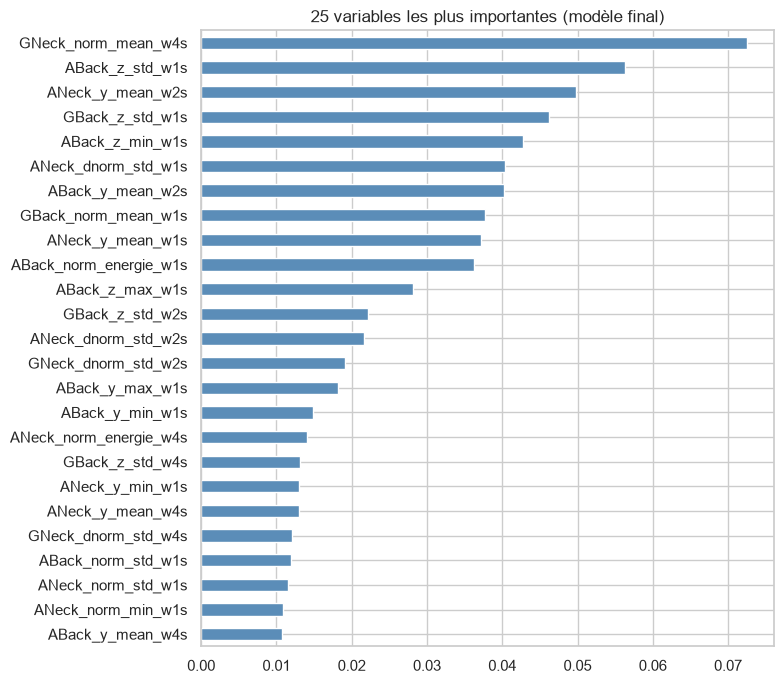

In [11]:
retenues = modeling.selected_features(final["model"], final["features"])
print(f"{len(retenues)} variables retenues sur {len(final['features'])}")
clf = final["model"].named_steps["clf"] if hasattr(final["model"], "named_steps") else final["model"]
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=retenues).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 7))
    imp.head(25).sort_values().plot.barh(ax=ax, color="#5b8db8")
    ax.set_title("25 variables les plus importantes (modèle final)")
    plt.tight_layout(); viz.savefig(fig, "04_importances"); plt.show()

### Performances selon le profil du chien

Un point = un chien de test. Avec 1 à 3 chiens par catégorie, ces graphiques sont **exploratoires** :
aucune conclusion statistique n'est possible.

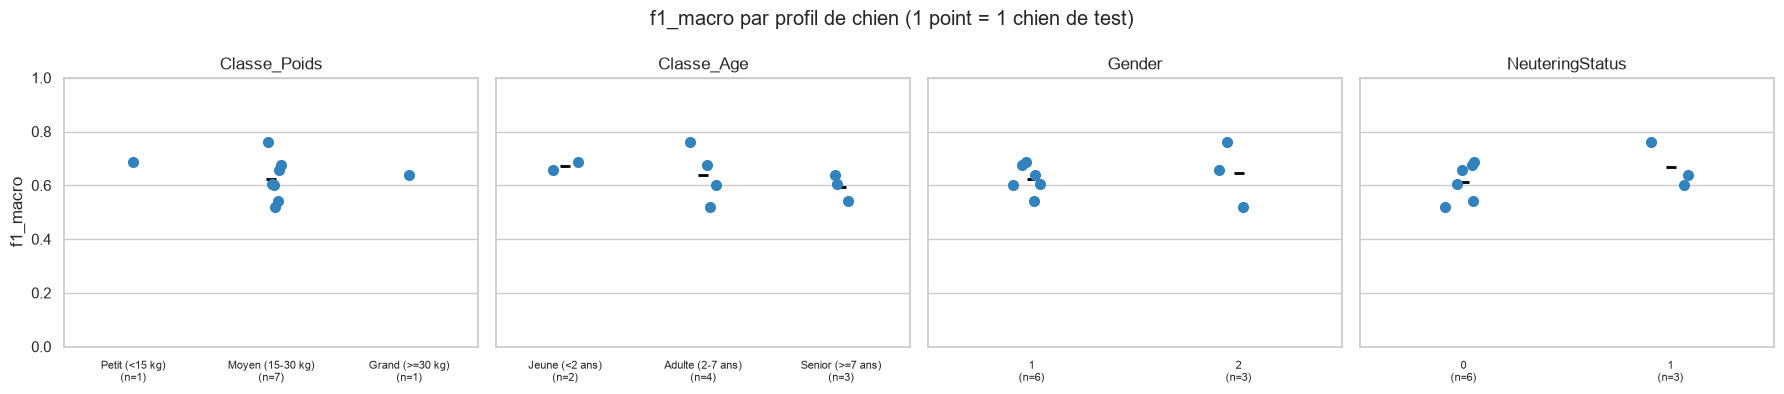

,Classe_Poids,n_chiens,moyenne,ecart_type
0,Petit (<15 kg),1,0.686,NaN
1,Moyen (15-30 kg),7,0.623,0.082
2,Grand (>=30 kg),1,0.638,NaN


In [12]:
fig = evaluation.plot_profiles(par_chien, dogs)
viz.savefig(fig, "04_profils"); plt.show()
display(evaluation.profile_table(par_chien, dogs, "Classe_Poids"))

Témoigne encore de la limite lié au nombre d'individu limité de l'étude. Néanmoins, pas de grosses différences à signaler sur les catégories ci-dessus.

### Frises chronologiques interactives

Axe horizontal = vrai temps de la séance. Les trous correspondent aux fenêtres exclues (non annotées,
impures ou de classe rare).

In [13]:
from ipywidgets import interact, Dropdown

seances = res[["DogID", "TestNum"]].drop_duplicates().sort_values(["DogID", "TestNum"])
options = {f"Chien {d} - test {t}": (d, t) for d, t in seances.itertuples(index=False)}

def frise(seance, vue):
    d, t = seance
    show = {"Tous": ("behavior_1", "behavior_2", "behavior_3"), "Behavior 1": ("behavior_1",),
            "Behavior 2": ("behavior_2",), "Behavior 3": ("behavior_3",)}[vue]
    viz.plot_timeline(res[(res["DogID"] == d) & (res["TestNum"] == t)], show=show,
                      title=f"Chien {d} - test {t}").show()

interact(frise, seance=Dropdown(options=options, description="Séance"),
         vue=Dropdown(options=["Tous", "Behavior 1", "Behavior 2", "Behavior 3"], description="Réel"));

interactive(children=(Dropdown(description='Séance', options={'Chien 16 - test 1': (16, 1), 'Chien 16 - test 2…